In [1]:
import torch
from datasets import load_dataset
from transformers import AutoModel

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Loading the dataset

Using a small (really cool) toy dataset of information about Pokémon that I've created previously.

More about the dataset [here](https://huggingface.co/datasets/cian-ps/pokedb-vl-1k).

In [2]:
ds = load_dataset("cian-ps/pokedb-vl-1k")
ds

DatasetDict({
    train: Dataset({
        features: ['identifier', 'ndex_id', 'name', 'image', 'markdown_text'],
        num_rows: 1025
    })
})

In [3]:
ds = ds["train"]

# 2. Loading the embedding model - llama-nemotron-embed-vl-1b-v2

llama-nemotron-embed-vl-1b-v2 was developed by NVIDIA for multimodal question-answering retrieval. The model can embed document pages in the form of image, text, or combined image–text inputs. Documents can be retrieved given a user query in text form. The model supports page images containing text, tables, charts, and infographics.

More about the model [here](https://huggingface.co/nvidia/llama-nemotron-embed-vl-1b-v2).

In [4]:
%%time

max_tokens = {
    "image": 2048,
    "text": 8192,
    "image_text": 10240,
}

EMBED_MODEL_NAME = "nvidia/llama-nemotron-embed-vl-1b-v2"
MODALITY = "image_text"

embed_model = AutoModel.from_pretrained(
    EMBED_MODEL_NAME,
    dtype=torch.bfloat16,
    trust_remote_code=True,
    attn_implementation="sdpa",
    device_map="auto",
).eval()

# set max number of tokens
embed_model.processor.p_max_length = max_tokens[MODALITY]
# Sets max number of tiles an image can be split. Each tile consumes 256 tokens.
embed_model.processor.max_input_tiles = 6
# Enables an extra tile with the full image at lower resolution
embed_model.processor.use_thumbnail = True

Loading weights:   0%|          | 0/600 [00:00<?, ?it/s]

CPU times: user 1.68 s, sys: 893 ms, total: 2.57 s
Wall time: 13.3 s


In [5]:
embed_model.device

device(type='cuda', index=0)

In [6]:
embed_model.processor.p_max_length

10240

### Let's view an example from the dataset:

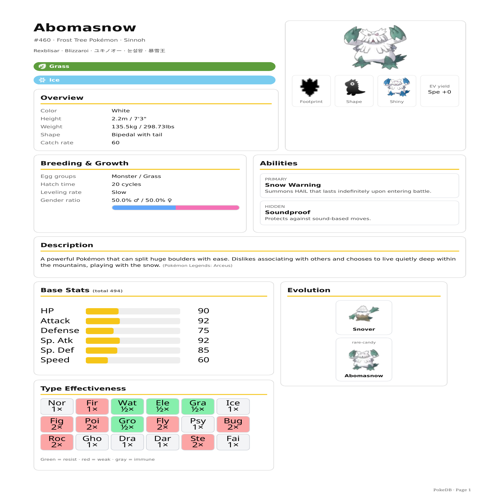

In [7]:
ds[0]["image"].resize(size=(500, 500))

In [8]:
from IPython.display import Markdown

Markdown(ds[0]["markdown_text"])

# Abomasnow

**National Dex #460** · Frost Tree Pokémon · Sinnoh region

Also known as *Rexblisar/Blizzaroi · ユキノオー · 눈설왕 · 暴雪王*.

**Type:** Grass / Ice

## Overview

Abomasnow is a Grass and Ice type with a **white** body color and a **bipedal with tail** body shape. It stands **2.2m (7'3")** tall and weighs **135.5kg (298.73lbs)**. Its catch rate is **60**, and when defeated it yields **1 EV in Attack**, and **1 EV in Sp. Atk**.

## Breeding and growth

Abomasnow belongs to the **Monster / Grass** egg groups. Eggs hatch after **20 cycles**, and it levels at a **Slow** rate. The species has a balanced gender ratio of roughly **50% male and 50% female**.

## Abilities

- **Snow Warning** *(primary)* — Summons HAIL that lasts indefinitely upon entering battle.
- **Soundproof** *(hidden)* — Protects against sound-based moves.

## Pokédex description

> A powerful Pokémon that can split huge boulders with ease. Dislikes associating with others and chooses to live quietly deep within the mountains, playing with the snow.

> — *Pokémon Legends: Arceus*

## Base stats

Abomasnow's base stat total is **494**, with HP **90**, Attack **92**, Defense **75**, Sp. Atk **92**, Sp. Def **85**, Speed **60**.

Its highest stats are **Attack, and Sp. Atk** (92 each).

## Evolution

The evolutionary line begins with **Snover**.
- **Abomasnow** — Leveling up

## Type matchups

As a Grass and Ice type, Abomasnow is:

- **Weak to** Fighting, Poison, Flying, Bug, Rock, Steel (2× damage)
- **Resistant to** Water, Electric, Grass, Ground (½× damage)
- **Neutral** to all other types


# 3. Creating a vector store

We keep it simple here and just use a safetensors file to store the embeddings.

In [9]:
import os
from pathlib import Path
from tqdm.auto import tqdm
from safetensors.torch import save_file, load_file

PROJECT_ROOT = Path.cwd().parent
EMBEDDINGS_FILE_PATH = PROJECT_ROOT / f"{MODALITY}_embeddings.safetensors"

BATCH_SIZE = 8

if os.path.exists(EMBEDDINGS_FILE_PATH):
    print(f"{MODALITY} embeddings already exists under: {EMBEDDINGS_FILE_PATH}")
else:
    assert embed_model.device.type == "cuda", "CUDA unavailable"
    print(f"Creating {MODALITY} embeddings...")

    embedding_chuncks = []
    for i in tqdm(range(0, len(ds), BATCH_SIZE)):
        batch = range(i, min(i+BATCH_SIZE, len(ds)))
        ds_chunck = ds.select(batch)
        chunck = {}
        if MODALITY == "image" or MODALITY == "image_text":
            chunck["images"] = ds_chunck["image"]
        if MODALITY == "text" or MODALITY == "image_text":
            chunck["texts"] = ds_chunck["markdown_text"]

        with torch.inference_mode():
            embed_chunck = embed_model.encode_documents(**chunck)
        
        embedding_chuncks.append(embed_chunck)
    
    embeddings = torch.cat(embedding_chuncks, dim=0)
    print(f"Created {MODALITY} embeddings of shape: {embeddings.shape}")
    save_file({f"{MODALITY}_embeddings": embeddings}, EMBEDDINGS_FILE_PATH)
    print(f"Saved to file: {EMBEDDINGS_FILE_PATH}")

image_text embeddings already exists under: /home/cian/multimodal-rag/nemotron-vl-rag-pipeline/image_text_embeddings.safetensors


In [10]:
loaded_embeddings = load_file(EMBEDDINGS_FILE_PATH, device=DEVICE.type)
loaded_embeddings

{'image_text_embeddings': tensor([[-0.7539, -1.9141,  1.2891,  ..., -1.1406, -1.7422,  2.0938],
         [-1.5703, -0.2793,  1.0781,  ..., -1.9688, -1.0625, -0.4062],
         [ 0.8438, -1.5469,  1.1406,  ..., -1.3984,  0.2734,  1.8828],
         ...,
         [-2.4219, -2.2344,  0.8867,  ...,  0.1104, -0.8164,  0.4121],
         [-0.4336, -1.0000, -0.2949,  ...,  0.5547, -0.5430, -0.1309],
         [ 0.5625, -0.9141,  0.6797,  ..., -1.4062, -1.3750, -1.3828]],
        device='cuda:0', dtype=torch.bfloat16)}

In [11]:
loaded_embeddings["image_text_embeddings"].shape

torch.Size([1025, 2048])

# 4. Matching an example query to the stored embeddings

Let's test it on a simple example:

In [19]:
def _l2_normalize(x: torch.Tensor, eps: float = 1e-12) -> torch.Tensor:
    return x / (x.norm(p=2, dim=-1, keepdim=True) + eps)

def _retrieve(
    embed_queries: torch.Tensor,
    embed_docs: torch.Tensor,
    top_k: int,
) -> tuple[torch.Tensor, torch.Tensor]:
    cos_sim = _l2_normalize(embed_queries) @ _l2_normalize(embed_docs).T
    cos_sim_flat = cos_sim.flatten()
    top_k_idx = torch.argsort(cos_sim_flat, descending=True)[:top_k]
    top_k_scores = cos_sim_flat[top_k_idx]
    return top_k_idx, top_k_scores

query = "Electric-type Pokémon known for its yellow fur, lightning bolt-shaped tail, and ability to \
generate electricity from the red sacs on its cheeks."

with torch.inference_mode():
    embed_query = embed_model.encode_documents(texts=[query])
embed_query, embed_query.shape

(tensor([[ 1.0625, -3.5156,  2.3438,  ...,  0.1592,  1.2031,  0.5195]],
        device='cuda:0', dtype=torch.bfloat16),
 torch.Size([1, 2048]))

In [20]:
indices, scores = _retrieve(
    embed_query,
    loaded_embeddings["image_text_embeddings"],
    10,
)

indices, scores

(tensor([ 662,  253,  256,  254, 1018,  257,  907,   75,  656,  969],
        device='cuda:0'),
 tensor([0.4551, 0.4355, 0.4316, 0.4277, 0.4258, 0.4238, 0.4219, 0.4180, 0.4180,
         0.4180], device='cuda:0', dtype=torch.bfloat16))

Electric-type Pokémon known for its yellow fur, lightning bolt-shaped tail, and ability to generate electricity from the red sacs on its cheeks.


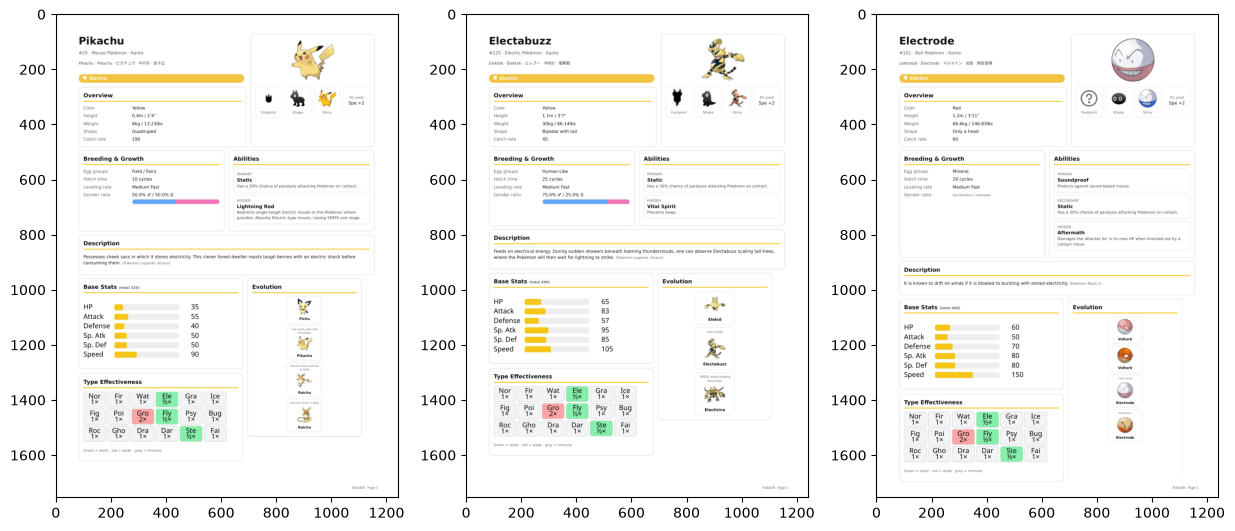

In [34]:
import matplotlib.pyplot as plt

top_3 = ds.select(indices[:3])

print(query)
plt.figure(figsize=(15, 10))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(top_3[i]["image"])


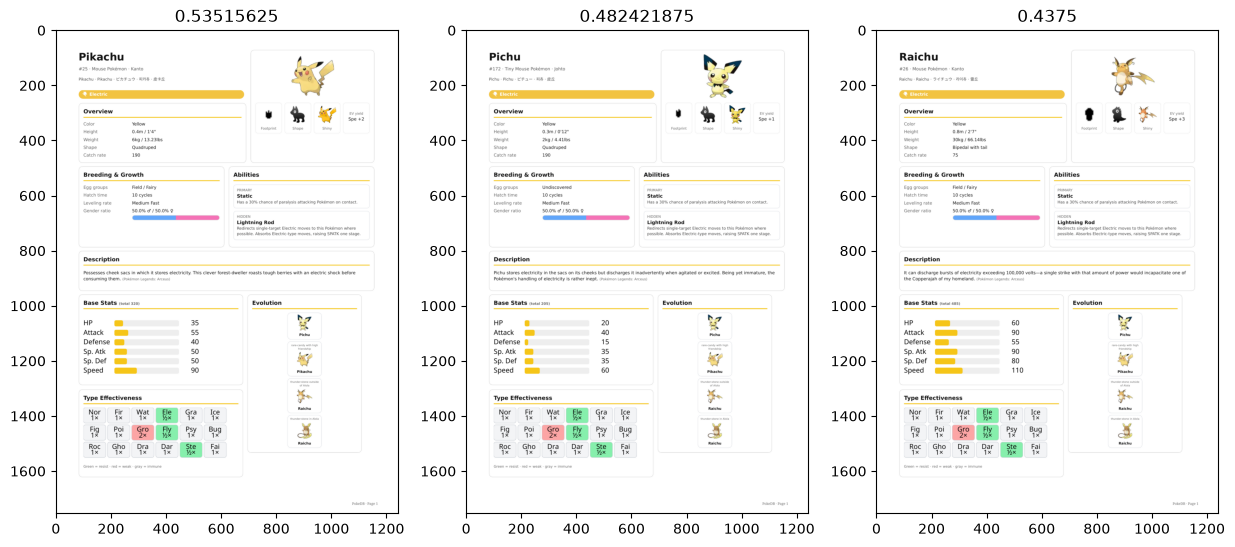

In [72]:
import requests
from PIL import Image

im_url = "https://img.pokemondb.net/artwork/large/pikachu.jpg"
query_image = Image.open(requests.get(im_url, stream=True).raw)

with torch.inference_mode():
    embed_image_text_query = embed_model.encode_documents(images=[query_image], texts=[query])

indices, scores = _retrieve(
    embed_image_text_query,
    loaded_embeddings["image_text_embeddings"],
    3,
)

plt.figure(figsize=(15, 10))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(ds.select(indices)[i]["image"])
    plt.title(str(scores.tolist()[i]))


**Note:** You can see that the model performs best on image + text queries.

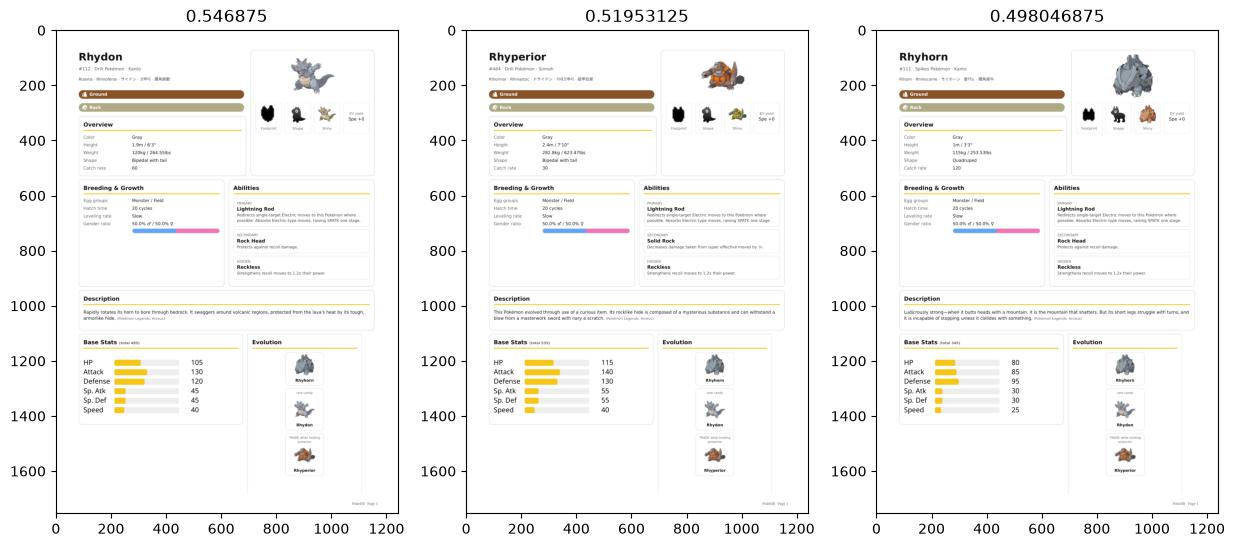

In [76]:
def plot_top_k_results(query, query_im=None, top_k=3):
    with torch.inference_mode():
        if query_im is not None:
            embed_query = embed_model.encode_documents(images=[query_im], texts=[query])
        else:
            embed_query = embed_model.encode_documents(texts=[query])
    indices, scores = _retrieve(
        embed_query,
        loaded_embeddings["image_text_embeddings"],
        top_k,
    )

    plt.figure(figsize=(15, 10))
    for i in range(top_k):
        plt.subplot(1, top_k, i+1)
        plt.imshow(ds.select(indices)[i]["image"])
        plt.title(str(scores.tolist()[i]))

query = "Rhydon is a dual-type Ground/Rock Pokémon introduced in Generation I. \
It evolves from Rhyhorn at level 42 and can further evolve into Rhyperior when traded while holding a Protector."
plot_top_k_results(query)

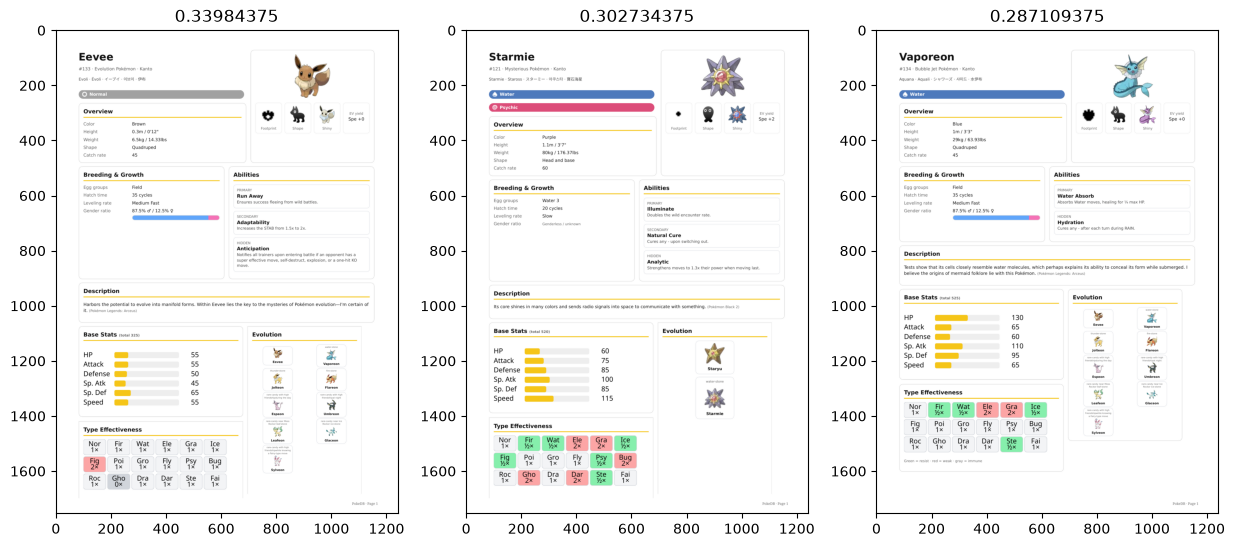

In [80]:
query = "Evolution of eevee when exposed to a water stone."
plot_top_k_results(query)